# 1. Exploratory Data Analysis

In [1]:
# ============================================================
# EDA 1: Memuat dan Memahami Dataset
# ============================================================

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Pengaturan tampilan
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

sns.set_theme(style="whitegrid")

# Lokasi dataset
data_path = Path("../data/data_gabungan/airguard_harian_semua_kota.csv")

# Membaca dataset
df = pd.read_csv(data_path)

# Mengubah kolom tanggal ke format datetime
df["tanggal"] = pd.to_datetime(df["tanggal"])

print("Dataset berhasil dimuat.")
print(f"Jumlah baris  : {df.shape[0]:,}")
print(f"Jumlah kolom : {df.shape[1]}")


Dataset berhasil dimuat.
Jumlah baris  : 17,550
Jumlah kolom : 18


In [29]:
input_path = Path(
    "../data/data_gabungan/airguard_harian_semua_kota.csv"
)

output_path = Path(
    "../data/data_gabungan/airguard_preprocessed.csv"
)

df_pre = pd.read_csv(input_path)

df_pre["tanggal"] = pd.to_datetime(
    df_pre["tanggal"]
)

print("Data berhasil dimuat")
print("Ukuran data:", df_pre.shape)

display(df_pre.head())


Data berhasil dimuat
Ukuran data: (17550, 18)


,kota,latitude,longitude,tanggal,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure,cloud_cover
0,Jakarta,-6.21,106.85,2022-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.17,78.67,0.30,11.60,257.62,"1,008.34",99.04
1,Jakarta,-6.21,106.85,2022-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.32,78.33,1.20,8.40,252.17,"1,007.92",97.92
2,Jakarta,-6.21,106.85,2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.42,76.46,0.20,5.52,201.00,"1,007.67",93.67
3,Jakarta,-6.21,106.85,2022-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.44,74.46,0.10,5.23,148.71,"1,008.60",95.88
4,Jakarta,-6.21,106.85,2022-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.54,82.29,15.90,4.95,165.25,"1,008.76",46.21


In [3]:
# Melihat informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17550 entries, 0 to 17549
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   kota                  17550 non-null  object        
 1   latitude              17550 non-null  float64       
 2   longitude             17550 non-null  float64       
 3   tanggal               17550 non-null  datetime64[ns]
 4   pm2_5                 15400 non-null  float64       
 5   pm10                  15400 non-null  float64       
 6   carbon_monoxide       15400 non-null  float64       
 7   nitrogen_dioxide      15400 non-null  float64       
 8   sulphur_dioxide       15400 non-null  float64       
 9   ozone                 15400 non-null  float64       
 10  us_aqi                15390 non-null  float64       
 11  temperature_2m        17550 non-null  float64       
 12  relative_humidity_2m  17550 non-null  float64       
 13  precipitation   

In [4]:
# Melihat nama seluruh kolom
print(df.columns.tolist())

['kota', 'latitude', 'longitude', 'tanggal', 'pm2_5', 'pm10', 'carbon_monoxide', 'nitrogen_dioxide', 'sulphur_dioxide', 'ozone', 'us_aqi', 'temperature_2m', 'relative_humidity_2m', 'precipitation', 'wind_speed_10m', 'wind_direction_10m', 'surface_pressure', 'cloud_cover']


In [5]:
# Statistik deskriptif seluruh kolom numerik
df.describe().T

,count,mean,min,25%,50%,75%,max,std
latitude,"17,550.00",-4.30,-7.80,-6.97,-5.68,-2.98,3.60,3.50
longitude,"17,550.00",109.48,98.67,106.85,109.86,112.75,119.43,5.36
tanggal,17550,2024-05-27 00:00:00.000000256,2022-01-01 00:00:00,2023-03-15 00:00:00,2024-05-27 00:00:00,2025-08-09 00:00:00,2026-10-21 00:00:00,NaN
pm2_5,"15,400.00",32.62,0.62,15.00,25.30,42.93,198.70,23.49
pm10,"15,400.00",40.24,0.90,19.84,32.03,53.31,203.49,27.29
carbon_monoxide,"15,400.00",901.15,59.12,352.85,667.73,"1,188.31","16,620.04",782.42
nitrogen_dioxide,"15,400.00",22.48,0.00,7.01,15.20,31.13,159.01,20.86
sulphur_dioxide,"15,400.00",13.40,0.05,3.18,6.59,20.61,127.36,14.83
ozone,"15,400.00",64.28,9.62,44.17,58.04,77.79,277.54,28.46
us_aqi,"15,390.00",95.89,13.25,61.58,83.33,125.49,279.08,41.53


In [6]:
# Ringkasan missing value
missing_summary = pd.DataFrame({
    "jumlah_missing": df.isna().sum(),
    "persentase_missing": df.isna().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="persentase_missing",
    ascending=False
)

display(missing_summary)


,jumlah_missing,persentase_missing
us_aqi,2160,12.31
ozone,2150,12.25
pm2_5,2150,12.25
pm10,2150,12.25
carbon_monoxide,2150,12.25
nitrogen_dioxide,2150,12.25
sulphur_dioxide,2150,12.25
relative_humidity_2m,0,0.00
surface_pressure,0,0.00
wind_direction_10m,0,0.00


In [7]:
# Jumlah data per kota
jumlah_per_kota = df["kota"].value_counts().sort_index()

display(jumlah_per_kota)

kota
Bandung        1755
Banjarmasin    1755
Jakarta        1755
Makassar       1755
Medan          1755
Palembang      1755
Pontianak      1755
Semarang       1755
Surabaya       1755
Yogyakarta     1755
Name: count, dtype: int64

In [8]:
# Rentang tanggal
print("Tanggal paling awal :", df["tanggal"].min().date())
print("Tanggal paling akhir:", df["tanggal"].max().date())
print("Jumlah hari unik    :", df["tanggal"].nunique())
print("Jumlah kota         :", df["kota"].nunique())

Tanggal paling awal : 2022-01-01
Tanggal paling akhir: 2026-10-21
Jumlah hari unik    : 1755
Jumlah kota         : 10


In [9]:
# ============================================================
# EDA 2: Pola Missing Value Berdasarkan Waktu
# ============================================================

kolom_polusi = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",
    "us_aqi"
]

# Jumlah kota yang memiliki data PM2.5 pada setiap tanggal
missing_harian = (
    df.groupby("tanggal")["pm2_5"]
      .agg(
          jumlah_kota_terisi="count",
          jumlah_kota_kosong=lambda x: x.isna().sum()
      )
      .reset_index()
)

display(missing_harian.head())

,tanggal,jumlah_kota_terisi,jumlah_kota_kosong
0,2022-01-01,0,10
1,2022-01-02,0,10
2,2022-01-03,0,10
3,2022-01-04,0,10
4,2022-01-05,0,10


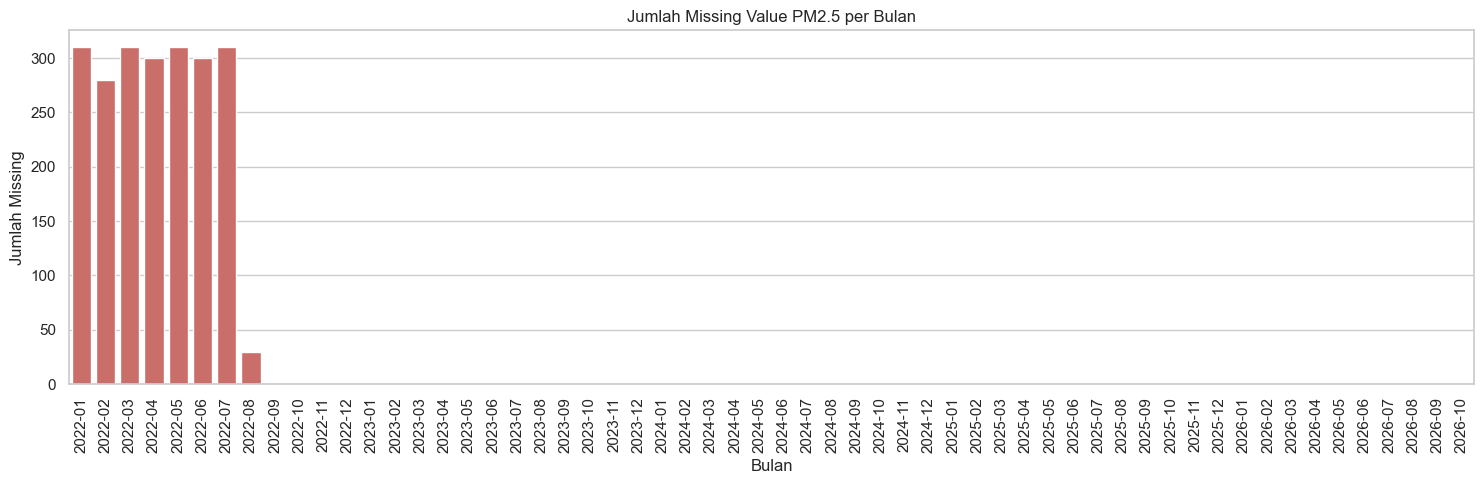

In [10]:
missing_bulanan = (
    df.assign(bulan=df["tanggal"].dt.to_period("M").astype(str))
      .groupby("bulan")["pm2_5"]
      .apply(lambda x: x.isna().sum())
      .reset_index(name="jumlah_missing")
)

plt.figure(figsize=(15, 5))

sns.barplot(
    data=missing_bulanan,
    x="bulan",
    y="jumlah_missing",
    color="#D95F59"
)

plt.title("Jumlah Missing Value PM2.5 per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Jumlah Missing")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [11]:
tanggal_pm25_terisi = df.loc[df["pm2_5"].notna(), "tanggal"]

print("PM2.5 mulai tersedia :", tanggal_pm25_terisi.min().date())
print("PM2.5 terakhir tersedia:", tanggal_pm25_terisi.max().date())

PM2.5 mulai tersedia : 2022-08-04
PM2.5 terakhir tersedia: 2026-10-21


In [12]:
# ============================================================
# EDA 3: Dataset Valid untuk Analisis Polusi
# ============================================================

# Menyimpan hanya baris yang memiliki nilai PM2.5
df_eda = df[df["pm2_5"].notna()].copy()

print("Ukuran dataset EDA:", df_eda.shape)
print("Periode:", df_eda["tanggal"].min().date(), "sampai", df_eda["tanggal"].max().date())
print("Missing PM2.5:", df_eda["pm2_5"].isna().sum())


Ukuran dataset EDA: (15400, 18)
Periode: 2022-08-04 sampai 2026-10-21
Missing PM2.5: 0


In [13]:
# Statistik PM2.5 per kota
statistik_kota = (
    df_eda.groupby("kota")["pm2_5"]
    .agg(
        jumlah_data="count",
        rata_rata="mean",
        median="median",
        minimum="min",
        maksimum="max",
        standar_deviasi="std"
    )
    .sort_values("rata_rata", ascending=False)
)

display(statistik_kota.round(2))


,jumlah_data,rata_rata,median,minimum,maksimum,standar_deviasi
kota,,,,,,
Jakarta,1540,67.18,68.19,0.64,150.09,25.00
Bandung,1540,55.40,51.40,0.66,127.40,20.29
Surabaya,1540,37.94,33.93,0.69,119.53,17.64
Yogyakarta,1540,35.50,29.95,0.70,126.24,20.93
Medan,1540,30.93,29.95,0.95,106.44,8.50
Semarang,1540,29.35,28.81,0.66,80.15,10.92
Pontianak,1540,18.80,13.16,0.71,198.70,20.08
Palembang,1540,18.47,15.03,0.62,162.58,15.17
Makassar,1540,18.07,17.08,0.63,91.09,7.29


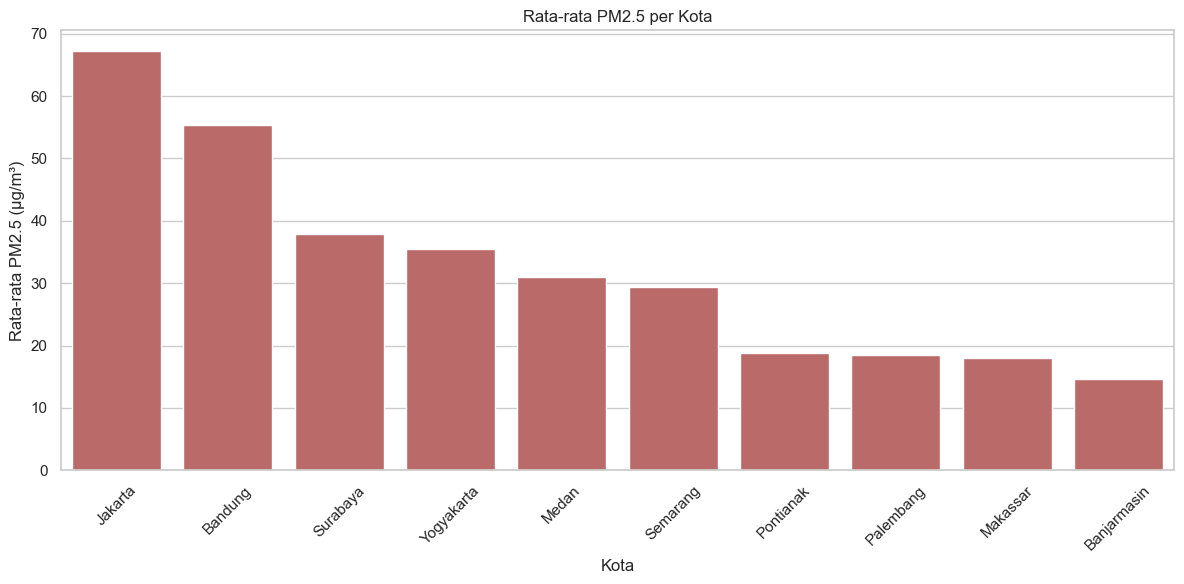

In [14]:
plt.figure(figsize=(12, 6))

urutan_kota = (
    df_eda.groupby("kota")["pm2_5"]
    .mean()
    .sort_values(ascending=False)
    .index
)

sns.barplot(
    data=df_eda,
    x="kota",
    y="pm2_5",
    order=urutan_kota,
    estimator="mean",
    errorbar=None,
    color="#C85C5C"
)

plt.title("Rata-rata PM2.5 per Kota")
plt.xlabel("Kota")
plt.ylabel("Rata-rata PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


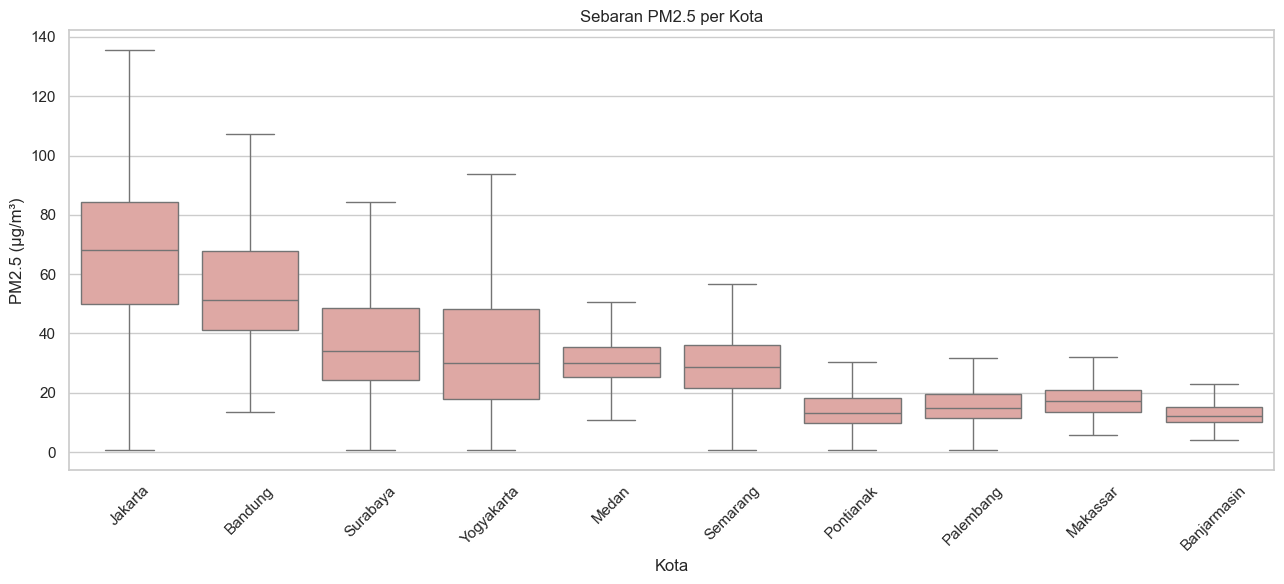

In [15]:
plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df_eda,
    x="kota",
    y="pm2_5",
    order=urutan_kota,
    color="#E8A09A",
    showfliers=False
)

plt.title("Sebaran PM2.5 per Kota")
plt.xlabel("Kota")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# EDA 4: Tren PM2.5 Bulanan
# ============================================================

# Membuat kolom bulan
df_eda["bulan"] = df_eda["tanggal"].dt.to_period("M").dt.to_timestamp()

# Rata-rata PM2.5 bulanan per kota
pm25_bulanan = (
    df_eda.groupby(["bulan", "kota"])["pm2_5"]
    .mean()
    .reset_index()
)

display(pm25_bulanan.head())


,bulan,kota,pm2_5
0,2022-08-01,Bandung,42.49
1,2022-08-01,Banjarmasin,14.32
2,2022-08-01,Jakarta,74.36
3,2022-08-01,Makassar,16.17
4,2022-08-01,Medan,33.52


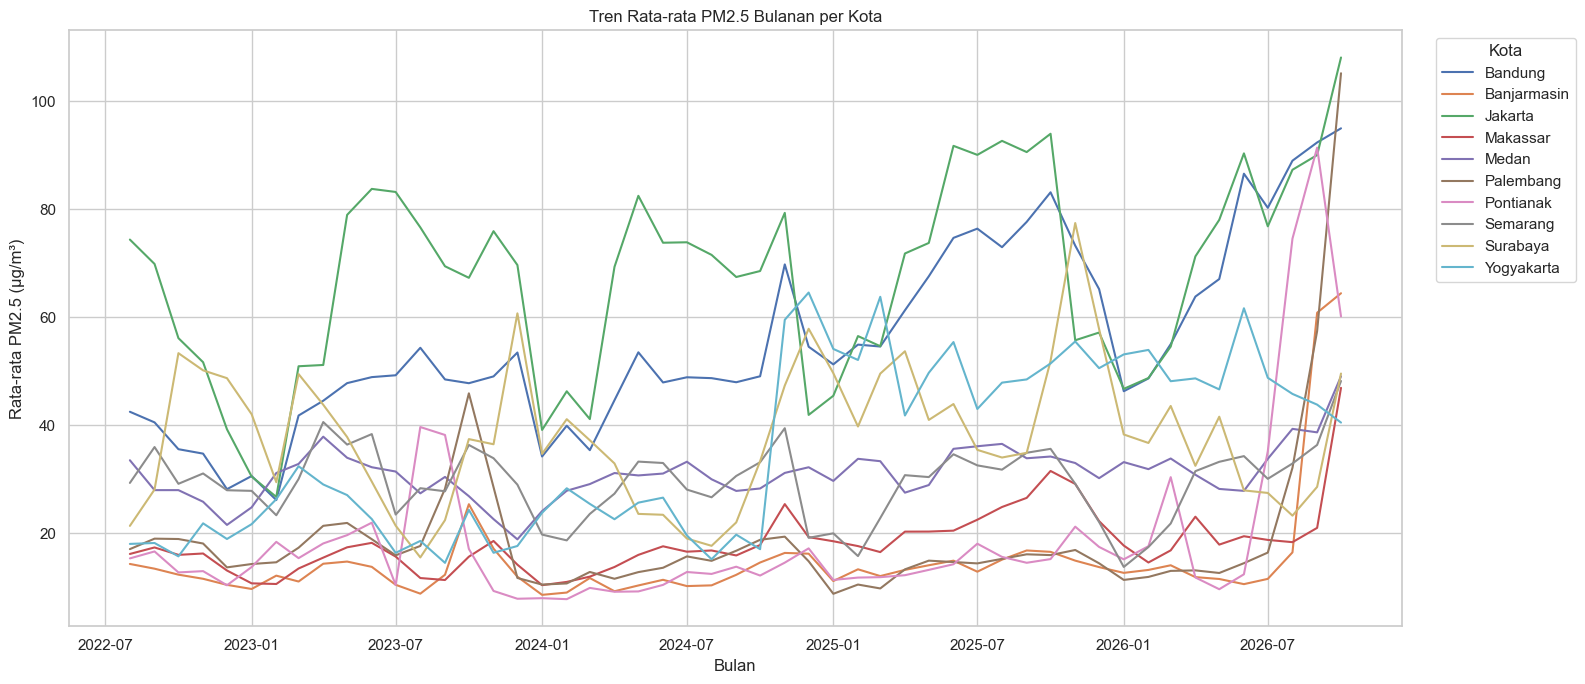

In [17]:
plt.figure(figsize=(16, 7))

sns.lineplot(
    data=pm25_bulanan,
    x="bulan",
    y="pm2_5",
    hue="kota",
    linewidth=1.5
)

plt.title("Tren Rata-rata PM2.5 Bulanan per Kota")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata PM2.5 (µg/m³)")
plt.legend(title="Kota", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


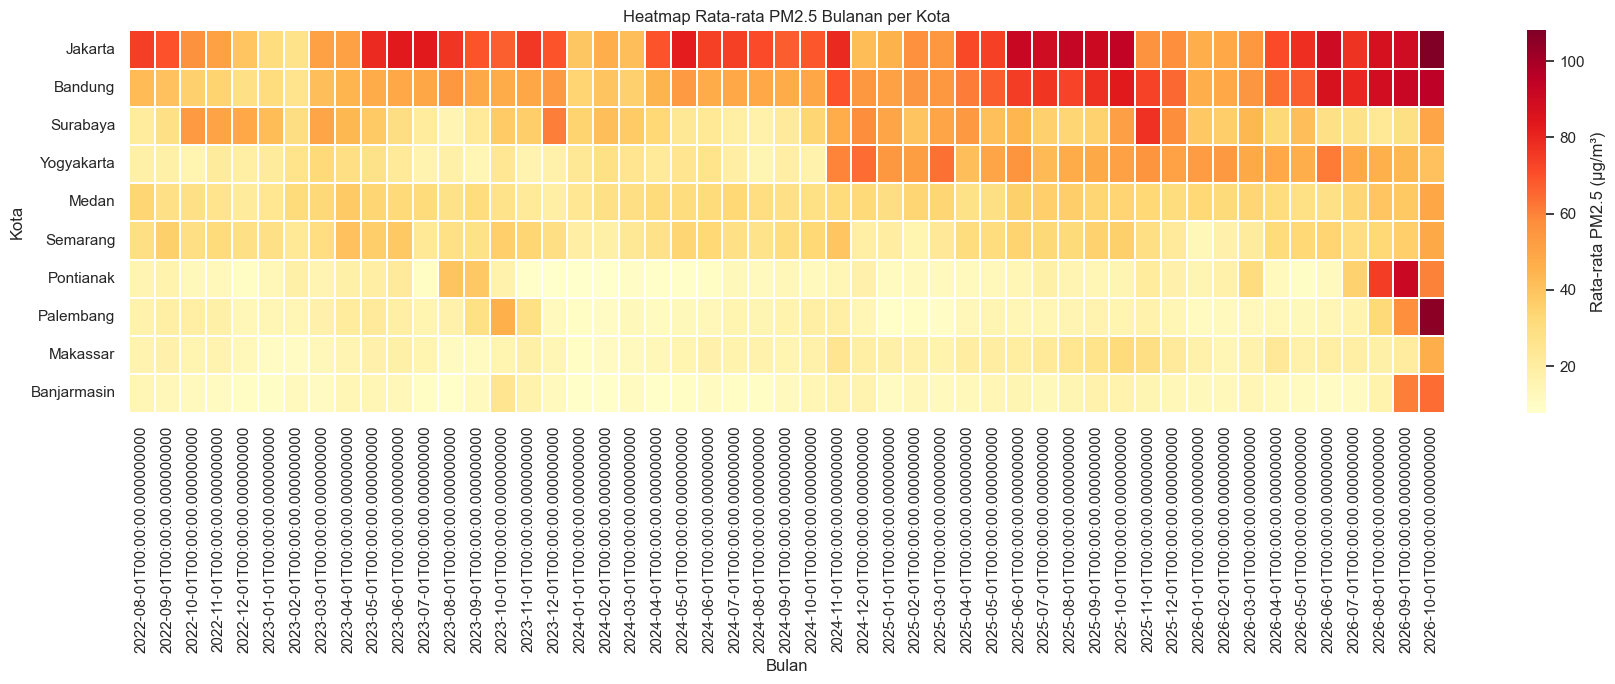

In [21]:
# Membuat tabel pivot
heatmap_pm25 = pm25_bulanan.pivot(
    index="kota",
    columns="bulan",
    values="pm2_5"
)

# Mengurutkan kota berdasarkan rata-rata PM2.5
urutan_kota = (
    df_eda.groupby("kota")["pm2_5"]
    .mean()
    .sort_values(ascending=False)
    .index
)

heatmap_pm25 = heatmap_pm25.reindex(urutan_kota)

plt.figure(figsize=(18, 7))

sns.heatmap(
    heatmap_pm25,
    cmap="YlOrRd",
    linewidths=0.3,
    cbar_kws={"label": "Rata-rata PM2.5 (µg/m³)"}
)

plt.title("Heatmap Rata-rata PM2.5 Bulanan per Kota")
plt.xlabel("Bulan")
plt.ylabel("Kota")
plt.tight_layout()
plt.show()


In [30]:
# ============================================================
# Pemeriksaan Missing Value Seluruh Atribut
# ============================================================

missing_check = pd.DataFrame({
    "jumlah_missing": df_pre.isna().sum(),
    "persentase_missing": df_pre.isna().mean() * 100
})

missing_check = missing_check.sort_values(
    by="persentase_missing",
    ascending=False
)

display(missing_check)


,jumlah_missing,persentase_missing
us_aqi,2160,12.31
ozone,2150,12.25
pm2_5,2150,12.25
pm10,2150,12.25
carbon_monoxide,2150,12.25
nitrogen_dioxide,2150,12.25
sulphur_dioxide,2150,12.25
relative_humidity_2m,0,0.00
surface_pressure,0,0.00
wind_direction_10m,0,0.00


In [32]:
kolom_polusi = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",
    "us_aqi"
]

kolom_cuaca = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_10m",
    "surface_pressure",
    "cloud_cover"
]

print("Missing pada variabel polusi:")
display(df_pre[kolom_polusi].isna().sum())

print("Missing pada variabel cuaca:")
display(df_pre[kolom_cuaca].isna().sum())


Missing pada variabel polusi:


pm2_5               2150
pm10                2150
carbon_monoxide     2150
nitrogen_dioxide    2150
sulphur_dioxide     2150
ozone               2150
us_aqi              2160
dtype: int64

Missing pada variabel cuaca:


temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
wind_direction_10m      0
surface_pressure        0
cloud_cover             0
dtype: int64

In [33]:
# Jumlah baris yang memiliki minimal satu missing pada variabel polusi
baris_polusi_missing = df_pre[kolom_polusi].isna().any(axis=1)

print("Baris dengan minimal satu nilai polusi kosong:",
      baris_polusi_missing.sum())

print("Baris dengan seluruh variabel polusi lengkap:",
      (~baris_polusi_missing).sum())

Baris dengan minimal satu nilai polusi kosong: 2160
Baris dengan seluruh variabel polusi lengkap: 15390


# 2. Preprocessing

In [34]:
# ============================================================
# PREPROCESSING AIRGUARD
# Target: Prediksi PM2.5 Hari Berikutnya
# ============================================================

from pathlib import Path

import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ------------------------------------------------------------
# 1. Membaca Dataset Mentah
# ------------------------------------------------------------

input_path = Path("../data/data_gabungan/airguard_harian_semua_kota.csv")
output_path = Path("../data/data_gabungan/airguard_preprocessed.csv")

df_pre = pd.read_csv(input_path)

print("Ukuran data awal:", df_pre.shape)
display(df_pre.head())


Ukuran data awal: (17550, 18)


,kota,latitude,longitude,tanggal,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure,cloud_cover
0,Jakarta,-6.21,106.85,2022-01-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.17,78.67,0.30,11.60,257.62,"1,008.34",99.04
1,Jakarta,-6.21,106.85,2022-01-02,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.32,78.33,1.20,8.40,252.17,"1,007.92",97.92
2,Jakarta,-6.21,106.85,2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.42,76.46,0.20,5.52,201.00,"1,007.67",93.67
3,Jakarta,-6.21,106.85,2022-01-04,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27.44,74.46,0.10,5.23,148.71,"1,008.60",95.88
4,Jakarta,-6.21,106.85,2022-01-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,26.54,82.29,15.90,4.95,165.25,"1,008.76",46.21


In [35]:
# ------------------------------------------------------------
# 2. Mengatur Tipe Data
# ------------------------------------------------------------

# Mengubah tanggal menjadi format datetime
df_pre["tanggal"] = pd.to_datetime(df_pre["tanggal"])

# Daftar kolom numerik
kolom_numerik = [
    "latitude",
    "longitude",
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",
    "us_aqi",
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_10m",
    "surface_pressure",
    "cloud_cover"
]

# Memastikan semua kolom numerik benar-benar bertipe numerik
for kolom in kolom_numerik:
    df_pre[kolom] = pd.to_numeric(
        df_pre[kolom],
        errors="coerce"
    )

print(df_pre.dtypes)


kota                            object
latitude                       float64
longitude                      float64
tanggal                 datetime64[ns]
pm2_5                          float64
pm10                           float64
carbon_monoxide                float64
nitrogen_dioxide               float64
sulphur_dioxide                float64
ozone                          float64
us_aqi                         float64
temperature_2m                 float64
relative_humidity_2m           float64
precipitation                  float64
wind_speed_10m                 float64
wind_direction_10m             float64
surface_pressure               float64
cloud_cover                    float64
dtype: object


In [36]:
# ------------------------------------------------------------
# 3. Memeriksa dan Menghapus Duplikasi
# ------------------------------------------------------------

jumlah_duplikat = df_pre.duplicated(
    subset=["kota", "tanggal"]
).sum()

print("Jumlah duplikasi kota-tanggal:", jumlah_duplikat)

df_pre = df_pre.drop_duplicates(
    subset=["kota", "tanggal"]
).copy()

Jumlah duplikasi kota-tanggal: 0


In [38]:
# ------------------------------------------------------------
# 4. Pemeriksaan Missing Value Awal
# ------------------------------------------------------------

missing_awal = pd.DataFrame({
    "jumlah_missing": df_pre.isna().sum(),
    "persentase_missing": df_pre.isna().mean() * 100
})

missing_awal = missing_awal.sort_values(
    by="persentase_missing",
    ascending=False
)

display(missing_awal)


,jumlah_missing,persentase_missing
pm2_5_lag_7,2220,12.65
pm2_5_lag_3,2180,12.42
pm2_5_lag_2,2170,12.36
us_aqi,2160,12.31
pm2_5_lag_1,2160,12.31
pm2_5,2150,12.25
pm10,2150,12.25
carbon_monoxide,2150,12.25
nitrogen_dioxide,2150,12.25
sulphur_dioxide,2150,12.25


In [39]:
# ------------------------------------------------------------
# 5. Menghapus Baris dengan Missing Value
# ------------------------------------------------------------

kolom_polusi = [
    "pm2_5",
    "pm10",
    "carbon_monoxide",
    "nitrogen_dioxide",
    "sulphur_dioxide",
    "ozone",
    "us_aqi"
]

kolom_cuaca = [
    "temperature_2m",
    "relative_humidity_2m",
    "precipitation",
    "wind_speed_10m",
    "wind_direction_10m",
    "surface_pressure",
    "cloud_cover"
]

kolom_wajib = kolom_polusi + kolom_cuaca

jumlah_sebelum_missing = len(df_pre)

df_pre = df_pre.dropna(
    subset=kolom_wajib
).copy()

jumlah_sesudah_missing = len(df_pre)

print("Baris sebelum penghapusan missing:",
      jumlah_sebelum_missing)

print("Baris sesudah penghapusan missing:",
      jumlah_sesudah_missing)

print("Baris yang dihapus:",
      jumlah_sebelum_missing - jumlah_sesudah_missing)


Baris sebelum penghapusan missing: 17550
Baris sesudah penghapusan missing: 15390
Baris yang dihapus: 2160


In [ ]:
# ------------------------------------------------------------
# 6. Mengurutkan Data
# ------------------------------------------------------------

df_pre = df_pre.sort_values(
    by=["kota", "tanggal"]
).reset_index(drop=True)

print(
    "Jumlah kota:",
    df_pre["kota"].nunique()
)

print(
    "Rentang tanggal:",
    df_pre["tanggal"].min().date(),
    "sampai",
    df_pre["tanggal"].max().date()
)

Jumlah kota: 10
Rentang tanggal: 2022-08-05 sampai 2026-10-21


In [ ]:
# ------------------------------------------------------------
# 7. Membuat Fitur Kalender
# ------------------------------------------------------------

df_pre["tahun"] = df_pre["tanggal"].dt.year
df_pre["bulan"] = df_pre["tanggal"].dt.month
df_pre["hari_dalam_minggu"] = df_pre["tanggal"].dt.dayofweek
df_pre["hari_dalam_tahun"] = df_pre["tanggal"].dt.dayofyear

In [43]:
# ------------------------------------------------------------
# 8. Membuat Fitur Lag PM2.5
# ------------------------------------------------------------

for lag in [1, 2, 3, 7]:
    df_pre[f"pm2_5_lag_{lag}"] = (
        df_pre
        .groupby("kota")["pm2_5"]
        .shift(lag)
    )

In [44]:
# ------------------------------------------------------------
# 9. Membuat Fitur Rolling Average
# ------------------------------------------------------------

df_pre["pm2_5_rolling_3"] = (
    df_pre
    .groupby("kota")["pm2_5"]
    .transform(
        lambda x: x.rolling(window=3).mean()
    )
)

df_pre["pm2_5_rolling_7"] = (
    df_pre
    .groupby("kota")["pm2_5"]
    .transform(
        lambda x: x.rolling(window=7).mean()
    )
)

df_pre["pm2_5_rolling_14"] = (
    df_pre
    .groupby("kota")["pm2_5"]
    .transform(
        lambda x: x.rolling(window=14).mean()
    )
)

In [45]:
# ------------------------------------------------------------
# 10. Membuat Target PM2.5 Hari Berikutnya
# ------------------------------------------------------------

df_pre["target_pm2_5"] = (
    df_pre
    .groupby("kota")["pm2_5"]
    .shift(-1)
)

In [46]:
# ------------------------------------------------------------
# 11. Menghapus Missing Value Akibat Feature Engineering
# ------------------------------------------------------------

kolom_fitur_wajib = [
    "pm2_5_lag_1",
    "pm2_5_lag_2",
    "pm2_5_lag_3",
    "pm2_5_lag_7",
    "pm2_5_rolling_3",
    "pm2_5_rolling_7",
    "pm2_5_rolling_14",
    "target_pm2_5"
]

jumlah_sebelum_feature_missing = len(df_pre)

df_pre = df_pre.dropna(
    subset=kolom_fitur_wajib
).copy()

jumlah_sesudah_feature_missing = len(df_pre)

print("Baris sebelum feature engineering missing:",
      jumlah_sebelum_feature_missing)

print("Baris sesudah feature engineering missing:",
      jumlah_sesudah_feature_missing)

print("Baris yang dihapus:",
      jumlah_sebelum_feature_missing -
      jumlah_sesudah_feature_missing)


Baris sebelum feature engineering missing: 15390
Baris sesudah feature engineering missing: 15250
Baris yang dihapus: 140


In [47]:
# ------------------------------------------------------------
# 12. Pemeriksaan Akhir
# ------------------------------------------------------------

missing_akhir = df_pre.isna().sum()

print("Jumlah total missing value:",
      missing_akhir.sum())

display(
    missing_akhir[missing_akhir > 0]
)


Jumlah total missing value: 0


Series([], dtype: int64)

In [48]:
# ------------------------------------------------------------
# 13. Menyimpan Dataset Preprocessed
# ------------------------------------------------------------

df_pre.to_csv(
    output_path,
    index=False
)

print("Dataset berhasil disimpan di:")
print(output_path)

print("Ukuran akhir dataset:",
      df_pre.shape)


Dataset berhasil disimpan di:
..\data\data_gabungan\airguard_preprocessed.csv
Ukuran akhir dataset: (15250, 30)


In [49]:
# Melihat hasil akhir
display(df_pre.head())
display(df_pre.tail())


,kota,latitude,longitude,tanggal,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure,cloud_cover,pm2_5_lag_1,pm2_5_lag_2,pm2_5_lag_3,pm2_5_lag_7,tahun,bulan,hari_dalam_minggu,hari_dalam_tahun,pm2_5_rolling_3,pm2_5_rolling_7,pm2_5_rolling_14,target_pm2_5
13,Bandung,-6.92,107.62,2022-08-18,34.83,50.14,"2,333.46",40.30,4.41,54.75,100.25,22.29,77.46,0.00,13.37,79.12,933.51,41.00,37.05,50.40,45.14,43.25,2022,8,3,230,40.76,39.45,41.85,37.58
14,Bandung,-6.92,107.62,2022-08-19,37.58,54.06,820.25,16.40,10.08,68.58,99.96,23.60,75.25,0.40,10.28,81.25,933.36,51.38,34.83,37.05,50.40,41.50,2022,8,4,231,36.49,38.89,41.18,40.23
15,Bandung,-6.92,107.62,2022-08-20,40.23,57.92,903.50,18.44,9.56,71.08,113.08,23.85,74.25,0.10,9.36,84.17,933.08,92.42,37.58,34.83,37.05,35.45,2022,8,5,232,37.55,39.57,40.29,41.29
16,Bandung,-6.92,107.62,2022-08-21,41.29,59.55,"1,015.58",17.72,8.02,82.75,115.67,22.57,80.46,10.10,5.58,150.33,933.30,98.79,40.23,37.58,34.83,31.77,2022,8,6,233,39.70,40.93,39.79,51.45
17,Bandung,-6.92,107.62,2022-08-22,51.45,74.45,"1,218.71",24.18,14.78,97.25,121.17,22.74,79.58,1.30,6.77,99.83,933.33,81.79,41.29,40.23,37.58,45.14,2022,8,0,234,44.32,41.83,40.78,59.32


,kota,latitude,longitude,tanggal,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,us_aqi,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m,surface_pressure,cloud_cover,pm2_5_lag_1,pm2_5_lag_2,pm2_5_lag_3,pm2_5_lag_7,tahun,bulan,hari_dalam_minggu,hari_dalam_tahun,pm2_5_rolling_3,pm2_5_rolling_7,pm2_5_rolling_14,target_pm2_5
15384,Yogyakarta,-7.80,110.37,2026-10-16,53.27,57.00,628.25,17.40,5.32,62.96,148.54,28.67,63.50,0.20,7.51,239.83,999.68,45.46,49.75,47.25,53.78,35.45,2026,10,4,289,50.09,49.07,41.94,48.08
15385,Yogyakarta,-7.80,110.37,2026-10-17,48.08,51.68,662.83,14.25,3.60,49.08,148.50,27.80,67.04,0.20,8.00,231.08,"1,000.25",49.38,53.27,49.75,47.25,53.64,2026,10,5,290,50.37,48.27,43.06,28.28
15386,Yogyakarta,-7.80,110.37,2026-10-18,28.28,32.00,481.96,9.63,2.57,55.92,94.96,28.08,70.17,0.90,7.33,234.38,999.97,87.88,48.08,53.27,49.75,43.24,2026,10,6,291,43.21,46.14,41.95,26.44
15387,Yogyakarta,-7.80,110.37,2026-10-19,26.44,29.40,431.71,10.82,3.40,61.25,80.33,28.18,71.50,0.70,7.64,245.92,"1,000.18",45.04,28.28,48.08,53.27,42.54,2026,10,0,292,34.27,43.84,41.23,32.75
15388,Yogyakarta,-7.80,110.37,2026-10-20,32.75,35.58,584.25,12.60,3.52,53.46,95.88,27.79,73.62,2.00,6.99,247.67,"1,000.92",70.83,26.44,28.28,48.08,53.78,2026,10,1,293,29.16,40.83,40.71,25.47
